# Problem 2 extension — Minimum sensors for a target error

Binary budget search with the existing **VND + Beam Search and Greedy**, evaluated using the actual overall sequential error including off-pair outcomes. Targets are $\epsilon\in\{0.1,0.2,0.3,0.4,0.5\}$. Each returned allocation and decision tree is explicitly verified to satisfy its target.

The result is the **smallest verified feasible budget visited by the heuristic budget search**, not a globally optimal minimum. Heuristic feasibility need not be monotone in the sensor budget.

Both modes reuse the existing Extended datasets. Before the sensor-bound cutoff, **test** selects 180 instances per dimension and **full** selects 2,160. The default cutoff retains 2,155 1D and 2,134 2D full-study instances. No dataset is regenerated.


In [1]:
from pathlib import Path
import sys, importlib, importlib.util
from IPython.display import display, Markdown

candidates = []
for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    candidates.extend([parent, parent/'problem-2-dual', parent/'problem-2-min-error-seq/problem-2-dual'])
HERE = next(p for p in candidates if (p/'dual_search.py').is_file())
sys.path.insert(0, str(HERE))
import dual_search
importlib.reload(dual_search)
import greedy_comparison
importlib.reload(greedy_comparison)
import budget_limited
importlib.reload(budget_limited)
spec = importlib.util.spec_from_file_location('dual_reporting', HERE/'reporting.py')
dual_reporting = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dual_reporting)

RUN_MODE = 'full'  # Applies when RUN_ANALYSIS=True; saved reports use their metadata.
RUN_ANALYSIS = True
SAVED_RESULTS = HERE/'results/test/e42f02f6d2a5d551'
RESUME = True
TARGET_ERRORS = (0.1, 0.2, 0.3, 0.4, 0.5)
BEAM_WIDTH = 3
MAX_ITERATIONS = 30
TIME_LIMIT_SECONDS = None  # Optional positive per-budget heuristic time limit.
BOOTSTRAP_RESAMPLES = 2000
BOOTSTRAP_SEED = 20261015

MAX_SENSOR_BOUND = 5000


## Budget search and feasibility

The saved $N_{\min}^{\mathrm{seq}}$ is the initial upper bound. The original Problem 1 solver reconstructs its perfect allocation and covering pair-test locations. A deterministic elimination tree is built from those locations and verified with the full sequential evaluator; the saved bound must match the reconstructed minimum.

For each target, start at `low=0`, `high=N_min_seq`. Independently evaluate each method at its bisection midpoint, retaining a feasible allocation/tree and lowering `high` when the actual error is at most the target; otherwise raise `low`. Stop when `high-low <= 1`. Zero-budget guessing is checked explicitly. No sensor-budget cap of 50 is applied to this search: its upper bound is the existing sequential minimum.

A timeout retains the last verified feasible solution and is marked incomplete; it is not evidence of infeasibility. Resume retries that budget. The complete allocation and tree are saved in the results, together with a trace of evaluated budgets.


In [2]:
if RUN_ANALYSIS:
    REPORT_MODE = RUN_MODE
    REPORT_TARGET_ERRORS = TARGET_ERRORS
    solutions, failures, OUTPUT = budget_limited.run_comparison(
        RUN_MODE, targets=TARGET_ERRORS, beam_width=BEAM_WIDTH,
        max_sensor_bound=MAX_SENSOR_BOUND,
        max_iterations=MAX_ITERATIONS, time_limit=TIME_LIMIT_SECONDS,
        resume=RESUME, run=True,
    )
else:
    import json
    OUTPUT = Path(SAVED_RESULTS)
    saved_info = json.loads((OUTPUT/'run_info.json').read_text())
    REPORT_MODE = saved_info['mode']
    REPORT_TARGET_ERRORS = tuple(saved_info['targets'])
    print(f'Loading saved {REPORT_MODE} results; no searches will run.')
    if REPORT_MODE != RUN_MODE or REPORT_TARGET_ERRORS != TARGET_ERRORS:
        print('RUN_MODE and TARGET_ERRORS apply only when RUN_ANALYSIS=True.')
    solutions = json.loads((OUTPUT/'solutions.json').read_text())
    failures = json.loads((OUTPUT/'failures.json').read_text())
import json
skipped_path = OUTPUT/'skipped.json'
skipped = json.loads(skipped_path.read_text()) if skipped_path.exists() else []
print('Skipped instances:', len(skipped))
assert all(r['verified_feasible'] and r['actual_error'] <= r['epsilon'] for r in solutions)
assert all(sum(r['allocation']) == r['N'] <= r['N_min_seq'] for r in solutions)
print('Report mode:', REPORT_MODE)
print('Report targets:', REPORT_TARGET_ERRORS)
print('Verified solutions:', len(solutions))
print('Failed instances:', len(failures))
print('Results:', OUTPUT)

if not any(r.get('method') == 'greedy' for r in solutions):
    print('Greedy results are not saved yet. Set RUN_ANALYSIS=True to compute them; matching VND results are reused.')


Upper-bound cutoff: 5000; included 4289/4320; skipped 31. Existing search checkpoints are reused.
Skipped instances: 31
Report mode: full
Report targets: (0.1, 0.2, 0.3, 0.4, 0.5)
Verified solutions: 42890
Failed instances: 0
Results: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/problem-2-dual/results/comparison_limited/full/39d435c5473c58f8


## Required sensors versus target error

Curves use instances with completed searches for **both methods at all five targets** once both methods have results, preserving paired comparisons. The green line shows VND + Beam Search and the red dashed line shows Greedy. Both show median sensor counts; shading spans the 25th–75th percentiles (interquartile range). The band describes variability across instances, not a confidence interval. No instances are removed for having extreme sensor counts. Mean counts and their 95% bootstrap confidence intervals remain in the numerical summary, alongside the median and quartiles.

Runtime includes perfect-allocation reconstruction/verification plus target-specific budget search and actual-error evaluation. Perfect setup is shared computationally but charged once per target to represent an independent target run. Accumulated measured times are retained on resume. Both components are shown separately.


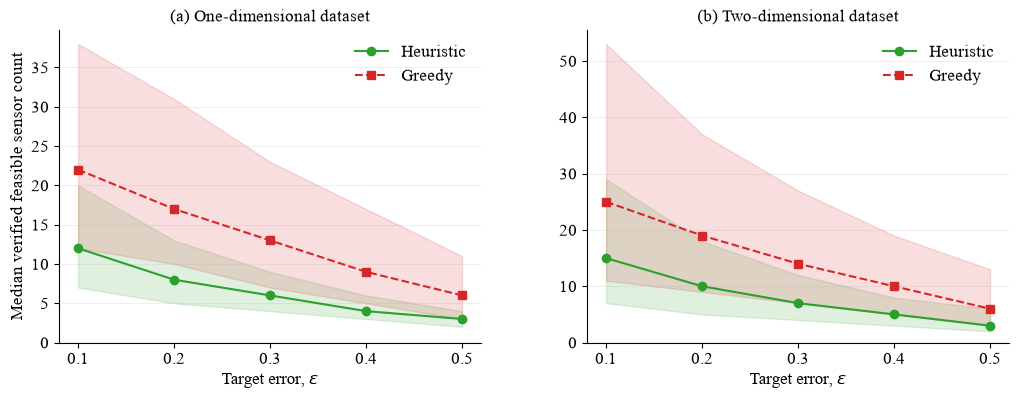

### Target-error summary

| dimension | method | epsilon | instances | median_required_sensors | q25_required_sensors | q75_required_sensors | mean_required_sensors | ci_low | ci_high | mean_runtime_seconds | mean_perfect_setup_seconds | mean_budget_search_seconds | mean_achieved_error | max_achieved_error | all_feasible |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1D | vnd_beam | 0.1 | 2155 | 12 | 7 | 20 | 20.3787 | 18.159 | 23.1359 | 2.53606 | 0.00587116 | 2.53019 | 0.0820722 | 0.0999996 | True |
| 1D | vnd_beam | 0.2 | 2155 | 8 | 5 | 13 | 10.8195 | 10.2078 | 11.6369 | 2.45322 | 0.00587116 | 2.44735 | 0.169844 | 0.199997 | True |
| 1D | vnd_beam | 0.3 | 2155 | 6 | 4 | 9 | 6.99397 | 6.82923 | 7.19259 | 2.44219 | 0.00587116 | 2.43632 | 0.256526 | 0.299986 | True |
| 1D | vnd_beam | 0.4 | 2155 | 4 | 3 | 6 | 4.91323 | 4.81205 | 5.02416 | 2.4229 | 0.00587116 | 2.41703 | 0.347748 | 0.399994 | True |
| 1D | vnd_beam | 0.5 | 2155 | 3 | 2 | 4 | 3.37587 | 3.31182 | 3.44317 | 2.38314 | 0.00587116 | 2.37727 | 0.442946 | 0.499886 | True |
| 1D | greedy | 0.1 | 2155 | 22 | 12 | 38 | 34.1313 | 32.0758 | 36.5249 | 0.0843185 | 0.00587116 | 0.0784473 | 0.0318002 | 0.099998 | True |
| 1D | greedy | 0.2 | 2155 | 17 | 10 | 31 | 23.7754 | 22.9828 | 24.6808 | 0.074144 | 0.00587116 | 0.0682728 | 0.121569 | 0.199999 | True |
| 1D | greedy | 0.3 | 2155 | 13 | 7 | 23 | 17.5193 | 17.0283 | 18.0594 | 0.0689395 | 0.00587116 | 0.0630683 | 0.240623 | 0.299999 | True |
| 1D | greedy | 0.4 | 2155 | 9 | 5 | 17 | 12.5921 | 12.2297 | 12.9666 | 0.0638999 | 0.00587116 | 0.0580287 | 0.356301 | 0.399999 | True |
| 1D | greedy | 0.5 | 2155 | 6 | 3 | 11 | 8.54617 | 8.28585 | 8.81488 | 0.060538 | 0.00587116 | 0.0546669 | 0.452287 | 0.499981 | True |
| 2D | vnd_beam | 0.1 | 2134 | 15 | 7 | 29 | 42.6476 | 35.4071 | 51.1009 | 4.36022 | 0.0136926 | 4.34653 | 0.0819264 | 0.0999984 | True |
| 2D | vnd_beam | 0.2 | 2134 | 10 | 5 | 18 | 17.8997 | 15.1156 | 22.3994 | 4.24477 | 0.0136926 | 4.23108 | 0.169991 | 0.199997 | True |
| 2D | vnd_beam | 0.3 | 2134 | 7 | 4 | 12 | 9.89691 | 9.12411 | 11.0076 | 4.1726 | 0.0136926 | 4.15891 | 0.259505 | 0.299984 | True |
| 2D | vnd_beam | 0.4 | 2134 | 5 | 3 | 8 | 6.24836 | 6.01967 | 6.49954 | 4.16981 | 0.0136926 | 4.15612 | 0.35148 | 0.399964 | True |
| 2D | vnd_beam | 0.5 | 2134 | 3 | 2 | 6 | 4.15089 | 4.04405 | 4.26149 | 4.1364 | 0.0136926 | 4.12271 | 0.449022 | 0.5 | True |
| 2D | greedy | 0.1 | 2134 | 25 | 11 | 53 | 53.9606 | 48.1688 | 60.502 | 0.107672 | 0.0136926 | 0.0939793 | 0.038541 | 0.0999967 | True |
| 2D | greedy | 0.2 | 2134 | 19 | 9 | 37 | 30.5572 | 28.487 | 33.0964 | 0.0880028 | 0.0136926 | 0.0743102 | 0.13401 | 0.199998 | True |
| 2D | greedy | 0.3 | 2134 | 14 | 7 | 27 | 20.1724 | 19.3421 | 21.2207 | 0.07951 | 0.0136926 | 0.0658174 | 0.246447 | 0.299998 | True |
| 2D | greedy | 0.4 | 2134 | 10 | 5 | 19 | 13.8201 | 13.3678 | 14.3018 | 0.0761491 | 0.0136926 | 0.0624565 | 0.359808 | 0.399991 | True |
| 2D | greedy | 0.5 | 2134 | 6 | 3 | 13 | 9.4044 | 9.11618 | 9.71043 | 0.070867 | 0.0136926 | 0.0571745 | 0.456144 | 0.499999 | True |

### Coverage

| dimension | selected_instances | included_instances | skipped_instances | complete_paired_instances | failed_instances | interrupted_targets |
| --- | --- | --- | --- | --- | --- | --- |
| 1D | 2160 | 2155 | 5 | 2155 | 0 | 0 |
| 2D | 2160 | 2134 | 26 | 2134 | 0 | 0 |

### Instances excluded by the sensor-bound cutoff

| dimension | case | field_model | K | M | N_min_seq | cutoff | reason |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | case_00458.csv | gaussian | 8 | 2 | 7367518 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 1 | case_00460.csv | gaussian | 8 | 2 | 7326 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 1 | case_00546.csv | gaussian | 9 | 2 | 98408 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 1 | case_00562.csv | gaussian | 9 | 4 | 8921 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 1 | case_00642.csv | gaussian | 10 | 3 | 6075 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00096.csv | gaussian | 4 | 2 | 8165 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00188.csv | gaussian | 5 | 2 | 11430 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00192.csv | gaussian | 5 | 3 | 6196 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00271.csv | gaussian | 6 | 2 | 6440741 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00272.csv | gaussian | 6 | 2 | 1388657744 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00275.csv | gaussian | 6 | 2 | 8603 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00287.csv | gaussian | 6 | 3 | 69932 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00365.csv | gaussian | 7 | 2 | 80341878 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00371.csv | gaussian | 7 | 3 | 49719 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00453.csv | gaussian | 8 | 2 | 13522 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00461.csv | gaussian | 8 | 3 | 10327 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00496.csv | gaussian | 8 | 6 | 299704 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00541.csv | gaussian | 9 | 2 | 380819 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00547.csv | gaussian | 9 | 2 | 159286669 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00556.csv | gaussian | 9 | 3 | 15749 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00557.csv | gaussian | 9 | 3 | 1122138 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00558.csv | gaussian | 9 | 3 | 5232 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00594.csv | gaussian | 9 | 7 | 14399 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00607.csv | gaussian | 9 | 8 | 29904 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00632.csv | gaussian | 10 | 2 | 6762679 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00635.csv | gaussian | 10 | 2 | 75825 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00638.csv | gaussian | 10 | 2 | 3286226 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00639.csv | gaussian | 10 | 2 | 28807 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00644.csv | gaussian | 10 | 3 | 5640 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00646.csv | gaussian | 10 | 3 | 1294212 | 5000 | sequential_upper_bound_exceeds_cutoff |
| 2 | case_00647.csv | gaussian | 10 | 3 | 288852 | 5000 | sequential_upper_bound_exceeds_cutoff |

In [5]:
# Reload labels and styling when rerunning this plotting cell.
import importlib.util
spec = importlib.util.spec_from_file_location('dual_reporting', HERE / 'reporting.py')
dual_reporting = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dual_reporting)

import matplotlib.pyplot as plt

figure, summary, coverage = dual_reporting.report(
    solutions, failures, OUTPUT, REPORT_TARGET_ERRORS,
    resamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED, skipped=skipped,
)
display(figure)
plt.close(figure)

def show_table(rows):
    if not rows:
        print('No rows available')
        return
    columns = list(rows[0])
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---']*len(columns)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(f'{row[k]:.6g}' if isinstance(row[k],float) else str(row[k]) for k in columns) + ' |')
    display(Markdown('\n'.join(lines)))

display(Markdown('### Target-error summary'))
show_table(summary)
display(Markdown('### Coverage'))
show_table(coverage)
if failures:
    display(Markdown('### Failed instances (first 20; all retained in failures.json)'))
    show_table(failures[:20])

if skipped:
    display(Markdown("### Instances excluded by the sensor-bound cutoff"))
    show_table(skipped)


## Saved results

- `solutions.json`: verified sensor counts, allocations, decision trees, actual errors, runtimes and budget-search traces.
- `verified_solutions.csv`: scalar results, including verified fallback solutions from interrupted searches.
- `summary.csv` and `coverage.csv`: paired summary statistics and exclusions.
- `required_sensors_vs_target.pdf` and `.png`: vector PDF and 600-dpi PNG exports.
- `failures.json` and `run_info.json`: failures, settings and source fingerprints.

Set `RUN_ANALYSIS=False` and select `SAVED_RESULTS` to rebuild reports directly from saved JSON files without running any searches or error evaluations. Existing Problem 1/2 algorithms and datasets are not modified by this extension.
